In [1]:
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from importlib import reload

Built target transform with target_type=classification, scaling=disabled
7999482


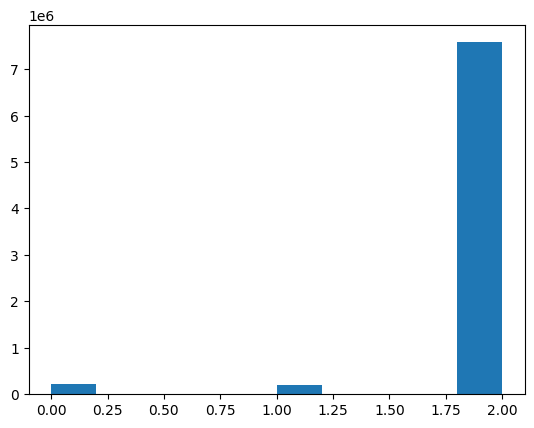

In [ ]:
# reload dataset module
from itertools import groupby
import dataloader
import random
import dataset
reload(dataset)
from dataset import SmartPixelsDataset
reload(dataloader)
from dataloader import create_dataloaders
import yaml
import matplotlib.pyplot as plt
from dataloader import get_target_transform

config = yaml.safe_load(Path("config/10783560/v3.yml").read_text())

train_image_files = [config["root"] + t[0] for t in config["train"]]
test_image_files = [config["root"] + t[0] for t in config["test"]]

train_label_files = [config["root"] + t[1] for t in config["train"]]
test_label_files = [config["root"] + t[1] for t in config["test"]]

all_image_files = train_image_files + test_image_files
all_label_files = train_label_files + test_label_files

target_transform = get_target_transform(target_type="classification")

ds = SmartPixelsDataset(image_paths=all_image_files, label_paths=all_label_files, target_transform=target_transform)

all_labels = ds.get_all_class_labels()


print(len(ds))

plt.hist(all_labels)
plt.show()

# print(train_files)
# train_files 

# ds = SmartPixelsDataset

# train_loader, val_loader, test_loader = create_dataloaders("config/10783560/v3.yml", target_type="classification", batch_size=128, shuffle=True, balance_classes=True)
# # train_loader, val_loader, test_loader = create_dataloaders("config/17180303/barrel-phys-pt/50x10.yml", target_type="classification", batch_size=128, shuffle=True, balance_classes=True)

# print(f"len(train_loader) = {len(train_loader)}")

# for x, y in tqdm(train_loader):
#     pass


In [15]:
from torchlogix.layers import FixedBinarization
import torch

layer = FixedBinarization(thresholds=torch.tensor([0.3, 0.6]))

inputs = torch.tensor([[0.2, 0.6, 0.4], [0.8, 0.3, 0.5]])

for inp in inputs:
    output = layer(inp)
    print(f"Input: {inp}, Output: {output}")

Input: tensor([0.2000, 0.6000, 0.4000]), Output: tensor([0., 0., 1., 0., 1., 0.])
Input: tensor([0.8000, 0.3000, 0.5000]), Output: tensor([1., 1., 0., 0., 1., 0.])


In [3]:
from dataloader import create_dataloaders

train_loader, val_loader, test_loader = create_dataloaders(
    "config/10783560/v3.yaml",
    batch_size=128,
    shuffle=True,
    val_size=0.01,
    input_type="full",  # y-profile, last-time-step
    target_type="regression" # classification
)

for event_idx in range(n_events):
    fig, ax = plt.subplots(figsize=(6, 5))
    
    def update(frame, idx=event_idx):  # Capture event_idx in closure
        ax.clear()
        ax.imshow(images[idx, frame], cmap='seismic', norm=TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax))
        ax.set_xlabel('X Pixel')
        ax.set_ylabel('Y Pixel')
        labels_str = ""
        for i, col in enumerate(labels.columns):
            val = labels.iloc[idx][col]
            if isinstance(val, float):
                labels_str += f"{col}={round(val, 2)}, "
            else:
                labels_str += f"{col}={val}, "
            if i % 4 == 3:
                labels_str += "\n"
        labels_str = labels_str.rstrip(', ')
        ax.set_title(f'Event {idx}, Time: {frame}\n{labels_str}', fontsize=10)
        return ax
    
    ani = FuncAnimation(fig, update, frames=images_.shape[1], interval=100, repeat=True)
    animations.append(ani)
    
    print(f"Animation {event_idx}:")
    display(HTML(ani.to_jshtml()))
    print("\n" + "="*80 + "\n")

FileNotFoundError: [Errno 2] No such file or directory: 'config/10783560/v3.yaml'

scalers/17180303/barrel-flat-pt
scalers/17180303/barrel-phys-pt
scalers/17180303/irradiated-barrel-flat-pt
scalers/17180303/endcap-phys-pt
scalers/17180303/endcap-flat-pt
scalers/17180303/irradiated-barrel-phys-pt


/tmp/ipykernel_1022698/1220386168.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[-1,0].set_xticklabels(names, rotation=90)
/tmp/ipykernel_1022698/1220386168.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[-1,1].set_xticklabels(names, rotation=90)


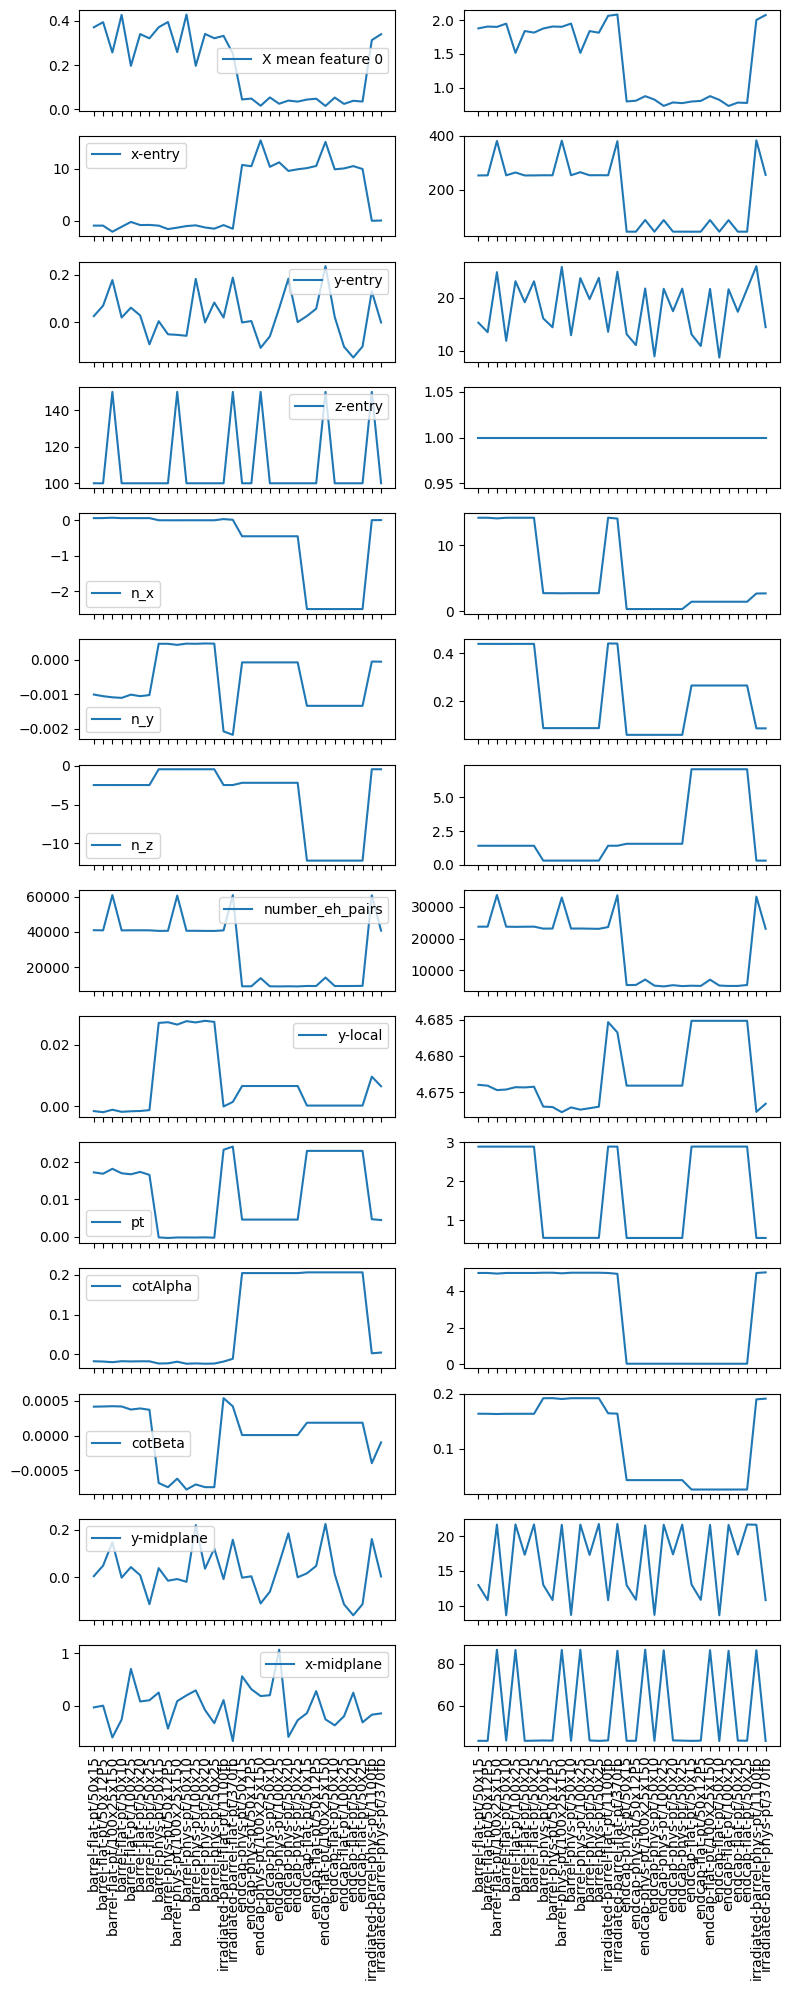

In [4]:
from glob import glob
import joblib
import matplotlib.pyplot as plt

names = []
x_means, y_means = {}, {}
x_stds, y_stds = {}, {}

for folder in glob("scalers/17180303/*"):
    print(folder)
    for subfolder in glob(f"{folder}/*"):
        # print(" ", subfolder)
        x_path = f"{subfolder}/scaler_X.pkl"
        y_path = f"{subfolder}/scaler_y.pkl"

        scaler_X = joblib.load(x_path)
        scaler_y = joblib.load(y_path)

        name = subfolder[17:]
        names.append(name)
        x_means[name] = scaler_X.mean_.tolist()
        x_stds[name] = scaler_X.scale_.tolist()
        y_means[name] = scaler_y.mean_.tolist()
        y_stds[name] = scaler_y.scale_.tolist()

        # print(x_path)

feature_names = ["x-entry", "y-entry", "z-entry", "n_x", "n_y", "n_z",
                 "number_eh_pairs", "y-local", "pt", "cotAlpha", "cotBeta", "y-midplane", "x-midplane"]

fig, axs = plt.subplots(14, 2, figsize=(8, 20), sharex=True)
axs[0,0].plot(names, [x_means[name][0] for name in names], label='X mean feature 0')
axs[0,1].plot(names, [x_stds[name][0] for name in names], label='X std feature 0')
axs[0,0].legend()
for i in range(13):
    axs[i+1,0].plot(names, [y_means[name][i] for name in names], label=feature_names[i])
    axs[i+1,1].plot(names, [y_stds[name][i] for name in names])
    axs[i+1,0].legend()
# rotate x ticks by 90 degrees
axs[-1,0].set_xticklabels(names, rotation=90)
axs[-1,1].set_xticklabels(names, rotation=90)
plt.tight_layout()
plt.show()



In [5]:
from dataloader import create_dataloaders

reshape = lambda df: df.values.reshape((20, 13, 21))
to_numpy = lambda df: df.values


train_loader, val_loader, test_loader = create_dataloaders(
    # "config/v3.yml",
    "config/17180303/barrel-phys-pt/50x25.yml",
    batch_size=128,
    shuffle=True,
)

for x, y in tqdm(train_loader):
    pass
    # print(x.shape, y.shape)
    # break


Built joint transform with input_type=full, target_type=regression, scaling=enabled


  0%|          | 0/8589 [00:00<?, ?it/s]/scratch/gpfs/IOJALVO/lg0508/conda/envs/smart_pixels/lib/python3.12/site-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
100%|██████████| 8589/8589 [01:17<00:00, 110.71it/s]


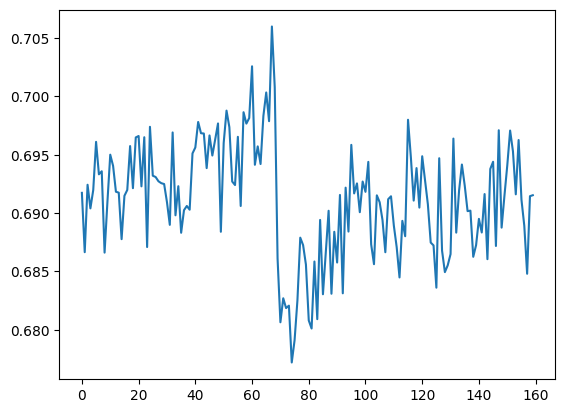

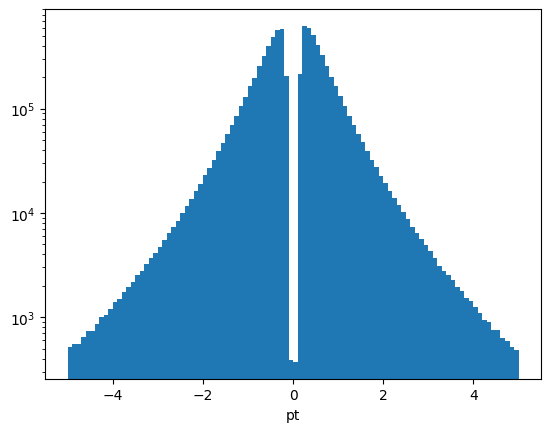

In [7]:
import matplotlib.pyplot as plt
import yaml
import glob

# ds_to_name = {
#     "dataset_2s": "barrel-phys-pt",
#     "dataset_3s": "barrel-flat-pt",
#     "dataset_6s": "endcap-phys-pt",
#     "dataset_7s": "endcap-flat-pt",
#     "dataset_8s": "irr-phys-pt",
#     "dataset_9s": "irr-flat-pt",
# }

# # base_path = "/scratch/gpfs/IOJALVO/lg0508/SmartPixels/17180303"

# data = {}

# for ds in glob.glob(f"{base_path}/*/*/labels*.parquet"):
#     arch = ds.split("/")[-2].split("_")[-1]
#     ds_name = f'{ds_to_name[ds.split("/")[-3]]}-{arch}'
#     file_number = int(f"{ds[-10]}{ds[-9]}")
#     df = pd.read_parquet(ds)
#     mean_pt = df["pt"].abs().mean()
#     if ds_name not in data:
#         data[ds_name] = ([], [])
#     data[ds_name][0].append(file_number)
#     data[ds_name][1].append(mean_pt)


all_pts = []

base_path = "/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/labels/"
means = []
for i, ds in enumerate(sorted(glob.glob(f"{base_path}/labels*.parquet"))):
    df = pd.read_parquet(ds)
    all_pts.append(df["pt"])
    mean_pt = df["pt"].abs().mean()
    means.append(mean_pt)

all_pts = pd.concat(all_pts)

plt.plot(range(len(means)), means) 
plt.show()

plt.hist(all_pts, bins=100, log=True)
plt.xlabel("pt")
plt.show()

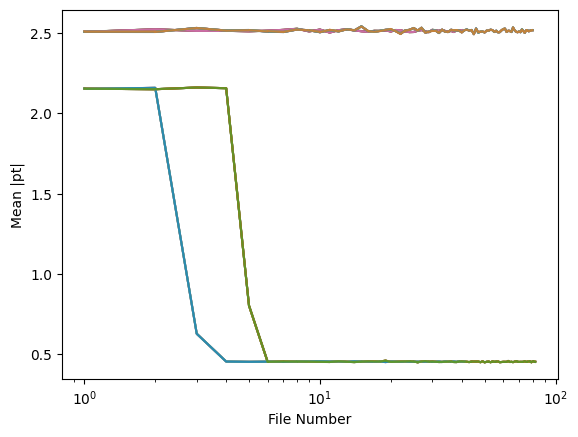

In [8]:
# print(data["irr-phys-pt"])

markers = ["o", "s", "D", "^", "v", "P", "*", "X", "<", ">"]
marker_sizes = [1, 8, 3, 4, 5, 6, 7, 8, 9, 10]

# for ds_name, marker, size in zip(data.keys(), markers, marker_sizes):
for ds_name in data.keys():
    # if "flat" in ds_name:
    #     continue
    # sort by file number
    sorted_indices = np.argsort(data[ds_name][0])
    x = np.array(data[ds_name][0])[sorted_indices]
    y = np.array(data[ds_name][1])[sorted_indices]
    # print(f"{ds_name}: {size}")
    plt.plot(
        # x, y, label=ds_name, alpha=0.7, marker=marker, markersize=size
        x, y, label=ds_name, alpha=0.7
    )

plt.xlabel("File Number")
plt.ylabel("Mean |pt|")
# make x-axis log scale
plt.xscale("log")
# plt.legend()
plt.show()

2.1544343599999998
2.1509536
2.16155072
2.1573234400000003
0.80136284
0.45061179999999995
0.45311668000000005
0.45241216
0.45119968
0.45084779999999997
0.4499272
0.45448555999999996
0.45097796
0.4495106
0.45223408
0.45344127999999995
0.45346008000000004
0.45309911999999997
0.45773347999999997
0.4503896
0.45156844000000007
0.45341084000000004
0.45353896
0.45410376
0.45273008000000003
0.44823451999999997
0.45296832000000004
0.45515804000000004
0.4520778
0.45270196
0.4512553199999999
0.4497804400000001
0.44993516000000006
0.45135031999999997
0.45130667999999996
0.45382172
0.44983088000000004
0.449366
0.45304279999999997
0.45393656000000004
0.45198204
0.45105059999999997
0.44934467999999994
0.45259864
0.45218988
0.45258820000000005
0.452296
0.4486033641345654
0.45391936
0.44777552
0.45106496
0.45239836000000005
0.4483646
0.45326896
0.45101087999999995
0.45210728
0.45318756
0.44856428
0.44954483999999995
0.45102
0.4508834
0.45047248000000006
0.45621712
0.44969928
0.45107736000000004
0.44902

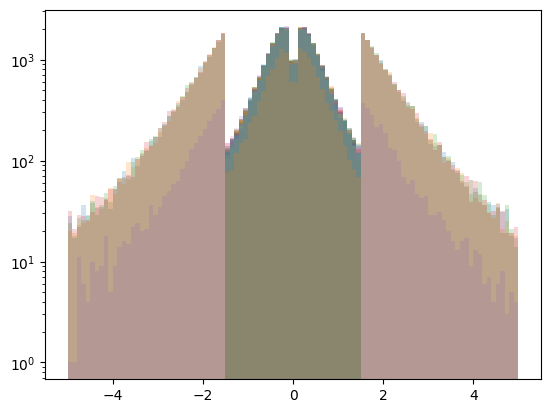

<Figure size 640x480 with 0 Axes>

In [9]:

# config = yaml.safe_load(open("config/v3.yml", "r"))
# config = yaml.safe_load(open("config/17180303/barrel-phys-pt/50x10.yml", "r"))
config = yaml.safe_load(open("config/17180303/endcap-phys-pt/50x10.yml", "r"))

label_paths = [config['root'] + item[1] for item in config['train'] + config['test']]

for path in label_paths:
    df = pd.read_parquet(path)
    print(df['pt'].abs().mean())
    plt.hist(df['pt'], bins=100, range=(-5, 5), alpha=0.2, label=Path(path).stem)

# set y-range to logarithmic scale
plt.yscale('log')
# plt.legend(ncol=3)
plt.show()
plt.tight_layout()

In [17]:
import importlib
import dataset
importlib.reload(dataset)
import tqdm
from glob import glob

images = sorted(glob("/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/recon3D/recon3D_d1730*.parquet"))
labels = sorted(glob("/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/labels/labels_d1730*.parquet"))


image_label_tuples = list(zip(images, labels))

for img, label in image_label_tuples:
    print(f"Image: {Path(img).name}, Label: {Path(label).name}")

# reshape = lambda df: df.values.reshape((20, 13, 21))
reshape = lambda x, y: (x.reshape((20, 13, 21)), y)

# ds = dataset.SmartPixelsDataset(image_label_tuples)#, transform=reshape)
ds = dataset.SmartPixelsDataset(images, labels, joint_transform=reshape)

print(ds.label_names)

print(len(ds))
for i in tqdm.tqdm(range(len(ds))):
    img, label = ds[i]


Image: recon3D_d17301.parquet, Label: labels_d17301.parquet
Image: recon3D_d17302.parquet, Label: labels_d17302.parquet
Image: recon3D_d17303.parquet, Label: labels_d17303.parquet
Image: recon3D_d17304.parquet, Label: labels_d17304.parquet
Image: recon3D_d17305.parquet, Label: labels_d17305.parquet
Image: recon3D_d17306.parquet, Label: labels_d17306.parquet
Image: recon3D_d17307.parquet, Label: labels_d17307.parquet
Image: recon3D_d17308.parquet, Label: labels_d17308.parquet
Image: recon3D_d17309.parquet, Label: labels_d17309.parquet
['x-entry', 'y-entry', 'z-entry', 'n_x', 'n_y', 'n_z', 'number_eh_pairs', 'y-local', 'pt', 'cotAlpha', 'cotBeta', 'y-midplane', 'x-midplane']
449971


100%|██████████| 449971/449971 [00:06<00:00, 67526.38it/s]


In [18]:

def load_and_balance_data(label_pattern, image_pattern):
    """Load and balance signal/background data from parquet files"""
    label_files = sorted(Path(".").glob(label_pattern))
    image_files = sorted(Path(".").glob(image_pattern))
    
    all_images, all_labels = [], []
    
    for label_file, image_file in zip(label_files, image_files):
        print(f"Processing: {label_file.name} & {image_file.name}")
        
        labels_df = pd.read_parquet(label_file)
        images_df = pd.read_parquet(image_file)
        
        # Create binary label
        labels_df["is_signal"] = labels_df["pt"].abs() > 0.2
        
        # Balance dataset by undersampling majority class
        n_signal = labels_df["is_signal"].sum()
        n_background = (~labels_df["is_signal"]).sum()
        n_samples = min(n_signal, n_background)
        
        # Sample equal amounts and shuffle
        balanced_labels = pd.concat([
            labels_df[labels_df["is_signal"]].sample(n=n_samples, random_state=42),
            labels_df[~labels_df["is_signal"]].sample(n=n_samples, random_state=42)
        ]).sample(frac=1, random_state=42)
        
        # Select corresponding images
        balanced_images = images_df.loc[balanced_labels.index]
        
        all_images.append(balanced_images.reset_index(drop=True))
        all_labels.append(balanced_labels.reset_index(drop=True))
    
    # Concatenate all files
    images = pd.concat(all_images, axis=0, ignore_index=True)
    labels = pd.concat(all_labels, axis=0, ignore_index=True)
    
    # Reshape images
    images = images.values.reshape(-1, 20, 13, 21)
    
    return images, labels

# Usage
images, labels = load_and_balance_data(
    "data/10783560/labels/labels_d1730?.parquet",
    "data/10783560/recon3D/recon3D_d1730?.parquet"
)

print(f"Loaded {images.shape[0]} balanced events.")

ValueError: No objects to concatenate

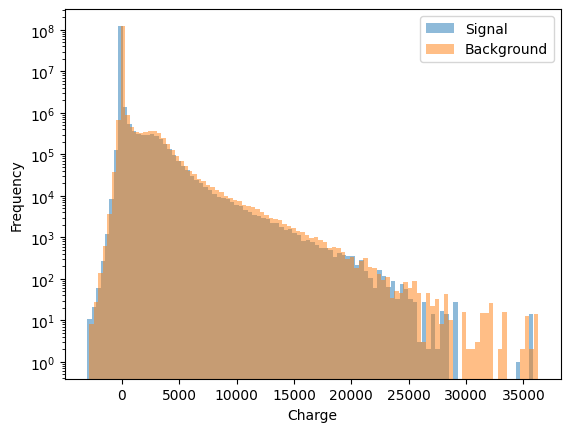

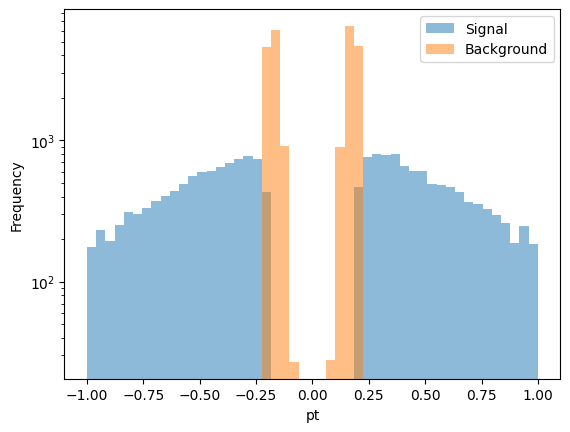

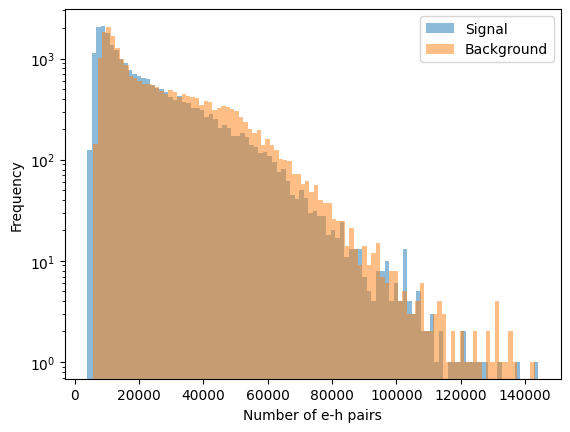

In [ ]:
plt.hist(images[labels['is_signal']].flatten(), bins=100, alpha=0.5, label='Signal')
plt.hist(images[~labels['is_signal']].flatten(), bins=100, alpha=0.5, label='Background')
plt.xlabel('Charge')
plt.ylabel('Frequency')
plt.yscale('log')
plt.legend()
plt.show()

plt.hist(labels['pt'][labels['is_signal']], bins=np.linspace(-1, 1, 50), alpha=0.5, label='Signal')
plt.hist(labels['pt'][~labels['is_signal']], bins=np.linspace(-1, 1, 50), alpha=0.5, label='Background')
plt.legend()
plt.xlabel('pt')
plt.ylabel('Frequency')
plt.yscale('log')
plt.show()

plt.hist(labels['number_eh_pairs'][labels['is_signal']], bins=100, alpha=0.5, label='Signal')
plt.hist(labels['number_eh_pairs'][~labels['is_signal']], bins=100, alpha=0.5, label='Background')
plt.legend()
plt.xlabel('Number of e-h pairs')
plt.ylabel('Frequency')
plt.yscale('log')
plt.show()


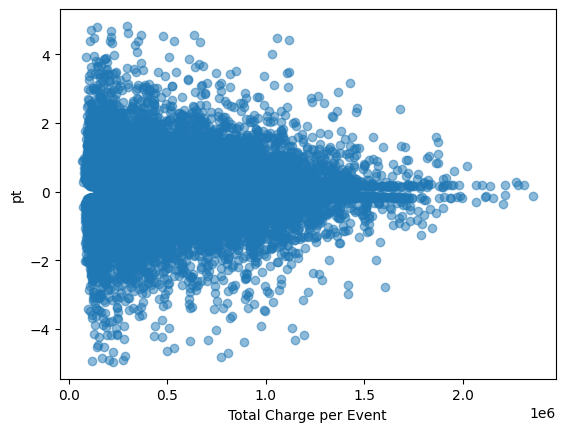

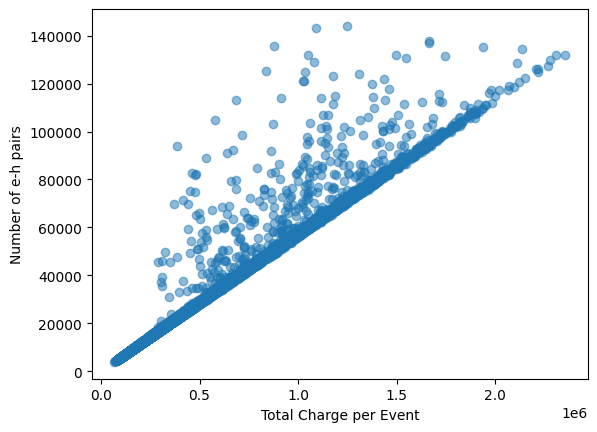

In [ ]:
charge_per_image = images.sum(axis=(1,2,3))
plt.scatter(charge_per_image, labels['pt'], alpha=0.5)
plt.xlabel('Total Charge per Event')
plt.ylabel('pt')
plt.show()

plt.scatter(charge_per_image, labels['number_eh_pairs'], alpha=0.5)
plt.xlabel('Total Charge per Event')
plt.ylabel('Number of e-h pairs')
plt.show()


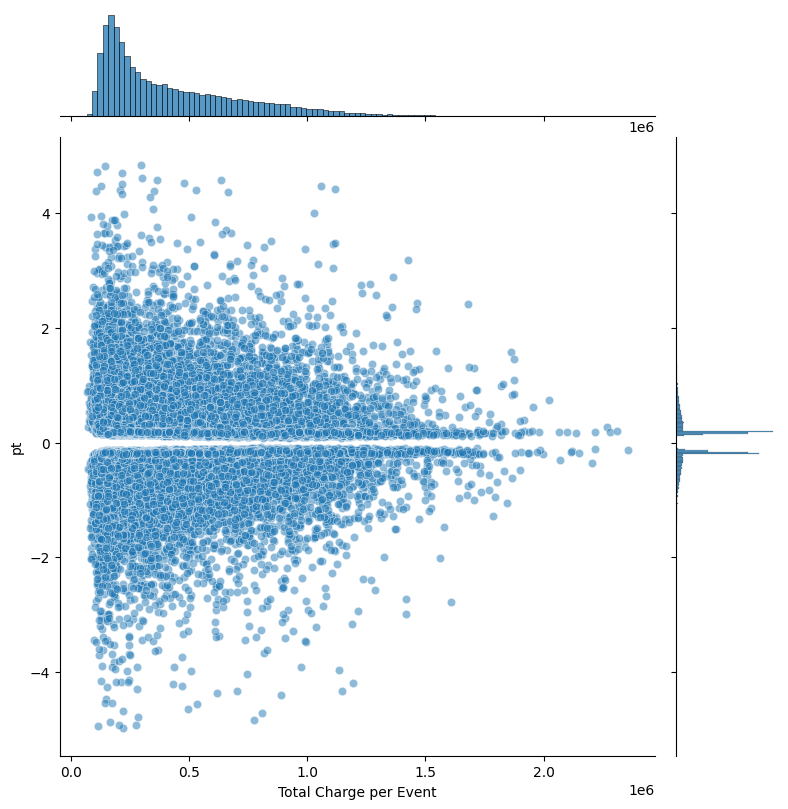

In [ ]:
import seaborn as sns

charge_per_image = images.sum(axis=(1,2,3))

g = sns.jointplot(x=charge_per_image, y=labels['pt'], 
                  alpha=0.5, height=8)
g.set_axis_labels('Total Charge per Event', 'pt')
plt.show()


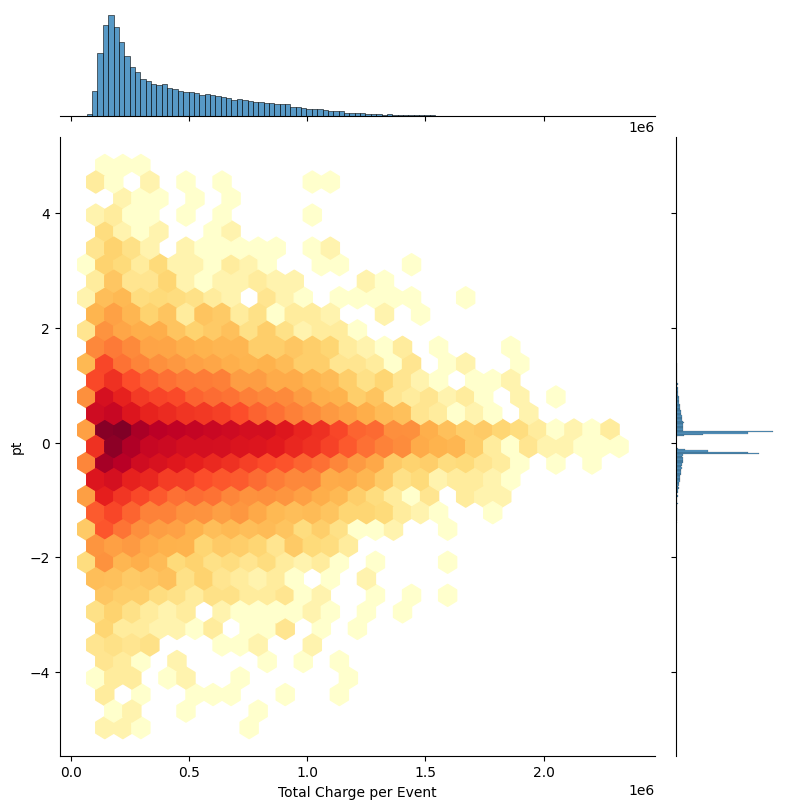

In [ ]:
import seaborn as sns
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt

g = sns.jointplot(x=charge_per_image, y=labels['pt'], 
                  kind='hex', height=8, 
                  cmap='YlOrRd',  # White to yellow to red
                  joint_kws={'norm': LogNorm(), 'gridsize': 30, 'mincnt': 1},
                  )
g.set_axis_labels('Total Charge per Event', 'pt')
plt.show()

In [21]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np

print(images)

# Calculate percentiles once
vmax = np.percentile(np.abs(images), 99)

n_events = 10
animations = []


for event_idx in range(n_events):
    fig, ax = plt.subplots(figsize=(6, 5))
    
    def update(frame, idx=event_idx):  # Capture event_idx in closure
        ax.clear()
        ax.imshow(images[idx, frame], cmap='seismic', norm=TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax))
        ax.set_xlabel('X Pixel')
        ax.set_ylabel('Y Pixel')
        labels_str = ""
        for i, col in enumerate(labels.columns):
            val = labels.iloc[idx][col]
            if isinstance(val, float):
                labels_str += f"{col}={round(val, 2)}, "
            else:
                labels_str += f"{col}={val}, "
            if i % 4 == 3:
                labels_str += "\n"
        labels_str = labels_str.rstrip(', ')
        ax.set_title(f'Event {idx}, Time: {frame}\n{labels_str}', fontsize=10)
        return ax
    
    ani = FuncAnimation(fig, update, frames=images_.shape[1], interval=100, repeat=True)
    animations.append(ani)
    
    print(f"Animation {event_idx}:")
    display(HTML(ani.to_jshtml()))
    print("\n" + "="*80 + "\n")

['/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/recon3D/recon3D_d17301.parquet', '/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/recon3D/recon3D_d17302.parquet', '/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/recon3D/recon3D_d17303.parquet', '/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/recon3D/recon3D_d17304.parquet', '/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/recon3D/recon3D_d17305.parquet', '/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/recon3D/recon3D_d17306.parquet', '/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/recon3D/recon3D_d17307.parquet', '/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/recon3D/recon3D_d17308.parquet', '/scratch/gpfs/IOJALVO/lg0508/SmartPixels/10783560/recon3D/recon3D_d17309.parquet']


UFuncTypeError: ufunc 'absolute' did not contain a loop with signature matching types <class 'numpy.dtypes.StrDType'> -> None

In [ ]:
# train-test split
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import TensorDataset

binary_labels = labels['is_signal'].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(images, binary_labels, test_size=0.2, random_state=42, stratify=binary_labels)
print(f"X_train.shape = {X_train.shape}, X_test.shape = {X_test.shape}")
print(f"y_train distribution:\n{pd.Series(y_train).value_counts()}")
print(f"y_test distribution:\n{pd.Series(y_test).value_counts()}")

import numpy as np

def symlog_transform(x, linthresh=1.0):
    """Symmetric log transform that handles negative values and zeros"""
    return np.sign(x) * np.log1p(np.abs(x) / linthresh)

def inverse_symlog_transform(x, linthresh=1.0):
    """Inverse transform"""
    return np.sign(x) * linthresh * (np.exp(np.abs(x)) - 1)

# Apply to your data
linthresh = 10.0  # Tune this - values below this are ~linear
X_train_transformed = symlog_transform(X_train, linthresh=linthresh)
X_test_transformed = symlog_transform(X_test, linthresh=linthresh)

# Then standardize (zero mean, unit variance)
mean = X_train_transformed.mean()
std = X_train_transformed.std()
X_train_normalized = (X_train_transformed - mean) / std
X_test_normalized = (X_test_transformed - mean) / std

train_dataset = TensorDataset(
    torch.tensor(X_train_normalized, dtype=torch.float32).unsqueeze(1), 
    torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
)


X_train.shape = (37940, 20, 13, 21), X_test.shape = (9486, 20, 13, 21)
y_train distribution:
1    18970
0    18970
Name: count, dtype: int64
y_test distribution:
1    4743
0    4743
Name: count, dtype: int64


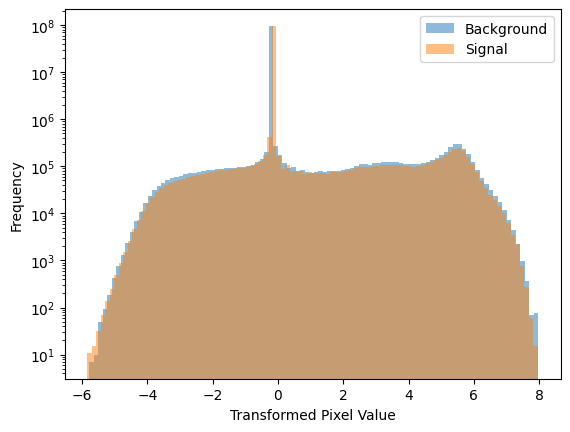

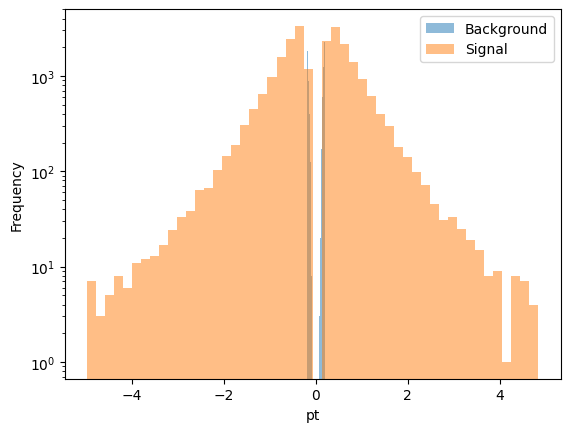

In [ ]:
# histogram of transformed pixel values
X_bg = X_train_normalized[y_train == 0]
X_signal = X_train_normalized[y_train == 1]
plt.hist(X_bg.flatten(), bins=100, alpha=0.5, label='Background')
plt.hist(X_signal.flatten(), bins=100, alpha=0.5, label='Signal')
plt.xlabel('Transformed Pixel Value')
plt.ylabel('Frequency')
plt.yscale('log')
plt.legend()
plt.show()

# plot of pt distributions
plt.hist(labels[labels['is_signal']==0]['pt'], bins=50, alpha=0.5, label='Background')
plt.hist(labels[labels['is_signal']==1]['pt'], bins=50, alpha=0.5, label='Signal')
plt.xlabel('pt')
plt.ylabel('Frequency')
plt.yscale('log')
plt.legend()
plt.show()

In [ ]:
# train a simple conv model in pytorch to classify signals vs backgrounds
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

model_conv3d = nn.Sequential(
    nn.Conv3d(1, 8, kernel_size=(3, 3, 3), padding=1),
    nn.ReLU(),
    nn.MaxPool3d((2, 2, 2)),
    nn.Conv3d(8, 16, kernel_size=(3, 3, 3), padding=1),
    nn.ReLU(),
    nn.MaxPool3d((2, 2, 2)),
    nn.Flatten(),
    nn.Linear(16 * 5 * 3 * 5, 64),
    nn.ReLU(),
    nn.Linear(64, 1),
    nn.Sigmoid()
)
criterion = nn.BCELoss()
optimizer_conv3d = optim.Adam(model_conv3d.parameters(), lr=0.001)

# print model summary
print(model_conv3d)
# total parameters
total_params = sum(p.numel() for p in model_conv3d.parameters())
print(f"Total parameters: {total_params}")

Sequential(
  (0): Conv3d(1, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (1): ReLU()
  (2): MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2), padding=0, dilation=1, ceil_mode=False)
  (3): Conv3d(8, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (4): ReLU()
  (5): MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2), padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1200, out_features=64, bias=True)
  (8): ReLU()
  (9): Linear(in_features=64, out_features=1, bias=True)
  (10): Sigmoid()
)
Total parameters: 80625


In [ ]:
train_dataset = TensorDataset(torch.tensor(X_train_transformed, dtype=torch.float32).unsqueeze(1), torch.tensor(y_train, dtype=torch.float32).unsqueeze(1))
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_dataset = TensorDataset(torch.tensor(X_test_transformed, dtype=torch.float32).unsqueeze(1), torch.tensor(y_test, dtype=torch.float32).unsqueeze(1))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

n_epochs = 10
for epoch in range(n_epochs):
    model_conv3d.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        optimizer_conv3d.zero_grad()
        outputs = model_conv3d(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_conv3d.step()
        running_loss += loss.item() * inputs.size(0)
    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}/{n_epochs}, Training Loss: {epoch_loss:.4f}")
    
    model_conv3d.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model_conv3d(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
    val_epoch_loss = val_loss / len(val_loader.dataset)
    print(f"Epoch {epoch+1}/{n_epochs}, Validation Loss: {val_epoch_loss:.4f}")
    


NameError: name 'DataLoader' is not defined

In [ ]:
# # train a minimal model (random forest)
from sklearn.ensemble import RandomForestClassifier
model_forest = RandomForestClassifier(n_estimators=100, random_state=42, verbose=1)
model_forest.fit(
    X_train_normalized.reshape(X_train_normalized.shape[0], -1), 
    y_train,
)


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:   22.0s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:   44.7s finished


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.2s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.3s finished


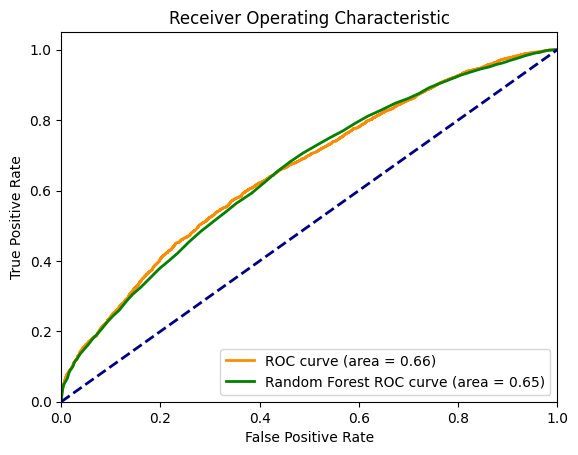

In [ ]:
# plot roc curve on test set
from sklearn.metrics import roc_curve, auc

def get_roc_curve(model, val_loader):
    if isinstance(model, RandomForestClassifier):
        y_scores = model.predict_proba(
            X_test_normalized.reshape(X_test_normalized.shape[0], -1)
        )[:, 1]
        fpr, tpr, thresholds = roc_curve(y_test, y_scores)
        roc_auc = auc(fpr, tpr)
        return fpr, tpr, roc_auc
    model.eval()
    all_outputs = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            all_outputs.extend(outputs.squeeze().numpy())
            all_labels.extend(labels.squeeze().numpy())
    fpr, tpr, thresholds = roc_curve(all_labels, all_outputs)
    roc_auc = auc(fpr, tpr)
    return fpr, tpr, roc_auc

fpr, tpr, roc_auc = get_roc_curve(model_conv3d, val_loader)
fpr_forest, tpr_forest, roc_auc_forest = get_roc_curve(model_forest, val_loader)

import matplotlib.pyplot as plt

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Conv3d (area = %0.2f)' % roc_auc)
plt.plot(fpr_forest, tpr_forest, color='green', lw=2, label='Random Forest (area = %0.2f)' % roc_auc_forest)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# dataX = pd.read_parquet("7331128/negative-charge/recon8t*.csv")
# labels_df = pd.read_parquet("7331128/negative-charge/labels*.csv")
dataX = pd.read_parquet("7331128/negative-charge/")
labels_df = pd.read_parquet("7331128/negative-charge/")
reshaped_dataX = dataX.values.reshape((len(dataX), 20, 13, 21))

print(labels_df.iloc[0])
plt.imshow(reshaped_dataX[0, 0, :, :], cmap='coolwarm')  # first time-step
plt.show()
plt.imshow(reshaped_dataX[0, -1, :, :], cmap='coolwarm')  # last time-step
plt.show()